# Credit Risk — decision-time data, chronology, and feature governance

**Decision question.** Are inputs available at application time, are future cohorts isolated, and can falling target rates be distinguished from label immaturity?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: credit-risk-decision-lab


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['reports/temporal_partitions.csv', 'reports/weekly_population.csv', 'reports/feature_inventory.csv', 'reports/feature_importance.csv', 'reports/feature_provenance.csv', 'reports/label_maturity_diagnostic.json', 'reports/run_metadata.json', 'reports/figures/weekly_default_rate.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,reports/temporal_partitions.csv,True,261
1,reports/weekly_population.csv,True,5162
2,reports/feature_inventory.csv,True,41772
3,reports/feature_importance.csv,True,6390
4,reports/feature_provenance.csv,True,2416
5,reports/label_maturity_diagnostic.json,True,604
6,reports/run_metadata.json,True,6933
7,reports/figures/weekly_default_rate.png,True,110305


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `reports/temporal_partitions.csv`

In [4]:
frame_1 = load_artifact('reports/temporal_partitions.csv')
audit_frame(frame_1, 'reports/temporal_partitions.csv')

#### Data-quality audit — `reports/temporal_partitions.csv`

,metric,value
0,rows,4
1,columns,7
2,missing cells,0
3,duplicate rows,0
4,numeric columns,6


,partition,rows,events,target_rate,first_week,last_week,weeks
0,development,1129770,35310,0.0313,0,54,55
1,calibration,171375,7735,0.0451,55,68,14
2,policy,73807,1734,0.0235,69,77,9
3,oot,151707,3215,0.0212,78,91,14


,count,mean,std,min,50%,max
rows,4.0000,"381,664.7500","500,513.1384","73,807.0000","161,541.0000","1,129,770.0000"
events,4.0000,"11,998.5000","15,749.2148","1,734.0000","5,475.0000","35,310.0000"
target_rate,4.0000,0.0303,0.0108,0.0212,0.0274,0.0451
first_week,4.0000,50.5000,34.9714,0.0000,62.0000,78.0000
last_week,4.0000,72.5000,15.5456,54.0000,72.5000,91.0000
weeks,4.0000,23.0000,21.4631,9.0000,14.0000,55.0000


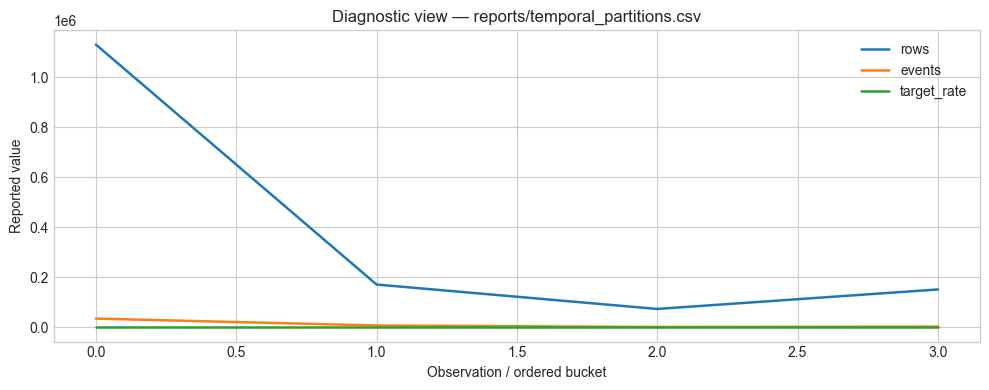

In [5]:
plot_numeric(frame_1, 'Diagnostic view — reports/temporal_partitions.csv')

## 3. Evidence table — `reports/weekly_population.csv`

In [6]:
frame_2 = load_artifact('reports/weekly_population.csv')
audit_frame(frame_2, 'reports/weekly_population.csv')

#### Data-quality audit — `reports/weekly_population.csv`

,metric,value
0,rows,92
1,columns,6
2,missing cells,0
3,duplicate rows,0
4,numeric columns,4


,WEEK_NUM,applications,defaults,default_rate,first_decision_date,last_decision_date
0,0,16735,400,0.0239,2019-01-01,2019-01-07
1,1,18841,472,0.0251,2019-01-08,2019-01-14
2,2,17476,465,0.0266,2019-01-15,2019-01-21
3,3,16108,419,0.0260,2019-01-22,2019-01-28
4,4,14309,404,0.0282,2019-01-29,2019-02-04
5,5,15335,407,0.0265,2019-02-05,2019-02-11
6,6,16385,445,0.0272,2019-02-12,2019-02-18
7,7,17238,462,0.0268,2019-02-19,2019-02-25


,count,mean,std,min,50%,max
WEEK_NUM,92.0000,45.5000,26.7021,0.0000,45.5000,91.0000
applications,92.0000,"16,594.1196","7,004.1976",825.0000,"17,088.5000","35,920.0000"
defaults,92.0000,521.6739,278.6590,21.0000,513.5000,"1,136.0000"
default_rate,92.0000,0.0301,0.0083,0.0177,0.0279,0.0521


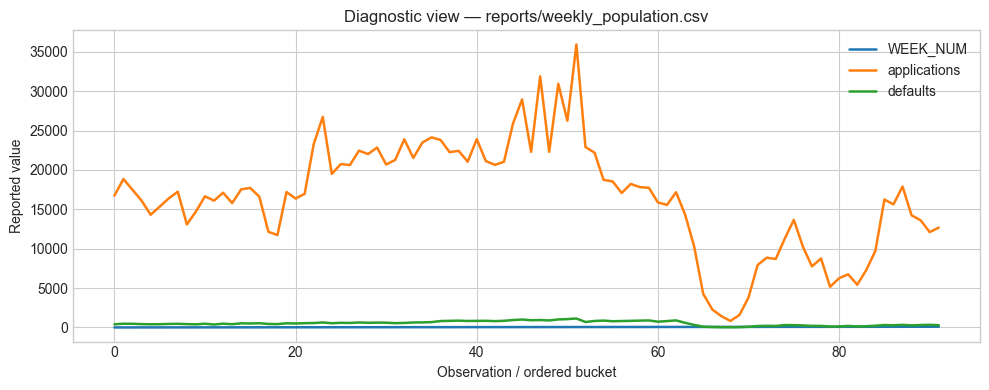

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/weekly_population.csv')

## 4. Evidence table — `reports/feature_inventory.csv`

In [8]:
frame_3 = load_artifact('reports/feature_inventory.csv')
audit_frame(frame_3, 'reports/feature_inventory.csv')

#### Data-quality audit — `reports/feature_inventory.csv`

,metric,value
0,rows,219
1,columns,9
2,missing cells,0
3,duplicate rows,0
4,numeric columns,2


,feature,description,source_table,transformed_type,development_missing_rate,oot_missing_rate,status,reason,date_treatment
0,clientscnt_136L,Number of applications associated with same em...,train_static_0,Float64,0.9996,1.0000,excluded,More than 98% missing in development,not applicable
1,deferredmnthsnum_166L,Number of deferred months.,train_static_0,Float64,0.0000,0.0000,excluded,Constant or unsupported type in development,not applicable
2,interestrategrace_34L,Interest rate during the grace period.,train_static_0,Float64,0.9846,0.9972,excluded,More than 98% missing in development,not applicable
3,isbidproductrequest_292L,Flag indicating if the product is a cross-sell.,train_static_0,Boolean,0.9916,0.9926,excluded,More than 98% missing in development,not applicable
4,lastapprcommoditytypec_5251766M,Commodity type of the last application.,train_static_0,String,0.0000,0.0000,excluded,Constant or unsupported type in development,not applicable
5,lastotherinc_902A,Amount of other income reported by the client ...,train_static_0,Float64,0.9979,0.9984,excluded,More than 98% missing in development,not applicable
6,lastotherlnsexpense_631A,Monthly expenses on other loans from the last ...,train_static_0,Float64,0.9979,0.9983,excluded,Sensitive/protected or proxy-risk policy,not applicable
7,lastrejectcommodtypec_5251769M,Commodity type of the last rejected application.,train_static_0,String,0.0000,0.0000,excluded,Constant or unsupported type in development,not applicable


,count,mean,std,min,50%,max
development_missing_rate,219.0000,0.4008,0.3682,0.0000,0.3183,1.0000
oot_missing_rate,219.0000,0.3454,0.3712,0.0000,0.2211,1.0000


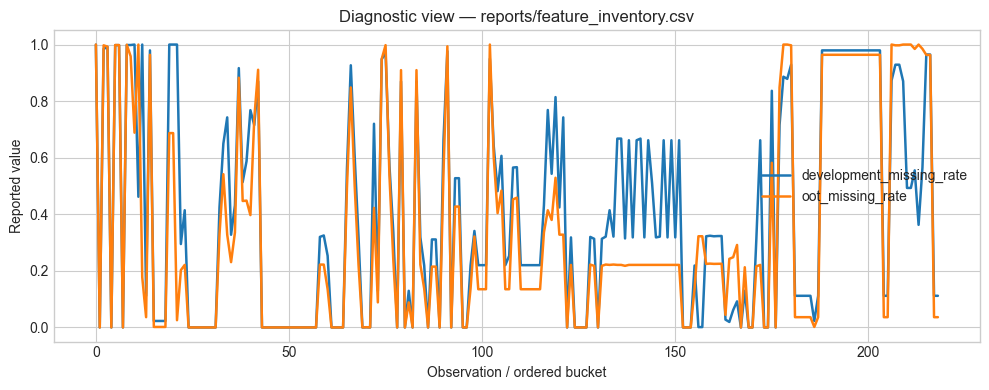

In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/feature_inventory.csv')

## 5. Evidence table — `reports/feature_importance.csv`

In [10]:
frame_4 = load_artifact('reports/feature_importance.csv')
audit_frame(frame_4, 'reports/feature_importance.csv')

#### Data-quality audit — `reports/feature_importance.csv`

,metric,value
0,rows,197
1,columns,2
2,missing cells,0
3,duplicate rows,0
4,numeric columns,1


,feature,gain
0,avgdpdtolclosure24_3658938P,0.0846
1,numrejects9m_859L,0.0229
2,pmtaverage_3A,0.0212
3,mobilephncnt_593L,0.0205
4,maxdbddpdtollast12m_3658940P,0.0205
5,numinstpaidearly3d_3546850L,0.0177
6,inittransactioncode_186L,0.0170
7,pctinstlsallpaidlate1d_3546856L,0.0160


,count,mean,std,min,50%,max
gain,197.0000,0.0051,0.0073,0.0000,0.0032,0.0846


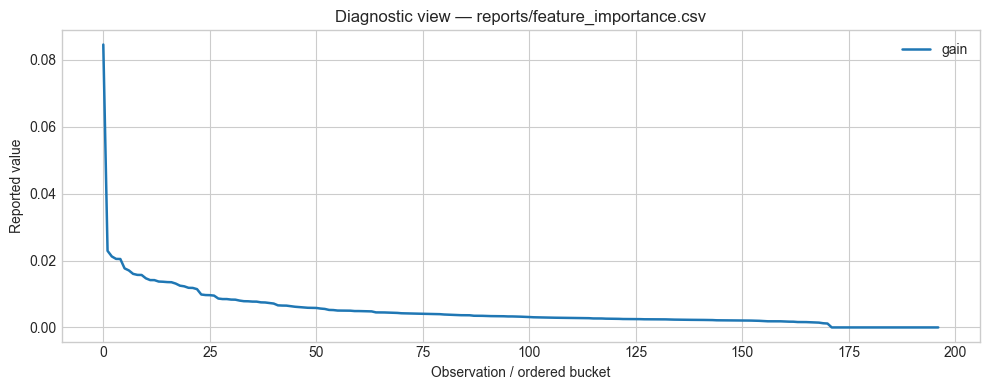

In [11]:
plot_numeric(frame_4, 'Diagnostic view — reports/feature_importance.csv')

## 6. Evidence table — `reports/feature_provenance.csv`

In [12]:
frame_5 = load_artifact('reports/feature_provenance.csv')
audit_frame(frame_5, 'reports/feature_provenance.csv')

#### Data-quality audit — `reports/feature_provenance.csv`

,metric,value
0,rows,8
1,columns,14
2,missing cells,5
3,duplicate rows,0
4,numeric columns,0


,feature_name,feature_family,raw_source,grain,transformation,observation_cutoff,available_at_decision,fit_partition,missing_treatment,model_role,exclusion_reason,leakage_risk,proxy_or_fairness_risk,validation
0,numeric_static,application static,train_static_0_*.parquet,application,Numeric fields eligible under frozen manifest,at date_decision,yes,development,native missing for XGBoost; median/binning for...,model,NaN,medium: definitions reviewed for post-decision...,credit-history variables may create access pro...,"feature inventory, time stability, baseline co..."
1,categorical_static,application static,train_static_0_* and train_static_cb_0,application,Low-cardinality categories eligible under froz...,at date_decision,yes,development,unknown/encoded from development,model,NaN,medium,category values may proxy protected characteri...,cardinality and missingness gates
2,relative_date_D,date recency,source columns ending D,application,date_decision - source date in days,at date_decision,yes,development,native missing,model,NaN,low after relative conversion,history length can proxy age/tenure,post-decision date check
3,missing_indicator,coverage,selected source fields,application,1 when source value is missing,at date_decision,yes,development,explicit binary,linear baseline,NaN,medium: provider/product eligibility signal,coverage can proxy channel or geography,cohort missingness monitoring
4,quantile_bin,nonlinear baseline,eligible numeric features,application,Ten development-fitted quantile bins with one-...,at date_decision,yes,development,imputer inside pipeline,binned-logit baseline,NaN,low,inherits source feature risks,locked OOT baseline comparison
5,case_id,identifier,train_base.case_id,application,No transformation,at decision,no model use,none,not applicable,excluded,identifier,high: identifier leakage,identity,excluded by contract
6,WEEK_NUM/MONTH/date_decision,partition/time,train_base,application,Used only for chronological partitions,at decision,audit only,none,not applicable,excluded,partition leakage,high: direct cohort leakage,time may proxy policy changes,excluded by contract
7,sensitive-token fields,protected/proxy,source fields matching birth/marital/education...,application,No transformation,at decision,excluded,development,not applicable,excluded,sensitive/proxy governance,high governance risk,protected or close proxy,frozen exclusion list


In [13]:
plot_numeric(frame_5, 'Diagnostic view — reports/feature_provenance.csv')

_No numeric series available for an automatic diagnostic plot._

## 7. Locked decision object — `reports/label_maturity_diagnostic.json`

In [14]:
payload = load_artifact('reports/label_maturity_diagnostic.json')
show_json(payload, 'reports/label_maturity_diagnostic.json')

#### reports/label_maturity_diagnostic.json

,field,value
0,reference_last_week,54
1,late_first_week,78
2,reference_default_rate,0.0313
3,late_default_rate,0.0212
4,relative_default_rate_change,-0.3219
5,reference_mean_weekly_applications,"20,541.2727"
6,late_mean_weekly_applications,"10,836.2143"
7,relative_volume_change,-0.4725
8,right_censoring_can_be_ruled_out,False
9,reason,The public target has no documented outcome-wi...


## 8. Locked decision object — `reports/run_metadata.json`

In [15]:
payload = load_artifact('reports/run_metadata.json')
show_json(payload, 'reports/run_metadata.json')

#### reports/run_metadata.json

,field,value
0,seed,20261004
1,fit_rows,600000
2,fit_weeks,"[0, 47]"
3,tune_weeks,"[48, 54]"
4,best_iteration,1194
5,feature_manifest,"{""numeric"": [""actualdpdtolerance_344P"", ""amtin..."
6,categorical_feature_count,19
7,exposure_proxy,credamount_770A
8,claim_boundary,Source target is not represented as regulatory...


## Visual evidence

![weekly_default_rate](../reports/figures/weekly_default_rate.png)

## Decision

**Use chronological development, calibration, policy, and locked-OOT windows. Preserve the current label-maturity warning and prohibit automated decline until outcome maturity is independently verified.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [16]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

The public source does not provide an outcome-window end date. Late-cohort target decline is therefore ambiguous between population drift and censoring.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.